# Vendor Performance Analysis

This notebook reads `vendor_sales_summary.csv`, the one-row-per-brand table built by `get_vendor_summary.py`, so it runs without the raw database.

**Corrections made in this version** (see the README's *Data quality* section):
* **Freight** is recorded per vendor invoice. The original join copied each vendor's total freight onto every one of its brands, so summing it counted the same freight hundreds of times. Freight is now allocated to brands by their share of the vendor's purchase dollars.
* **Gross profit** is now sales minus the cost of the units actually sold (`TotalSalesQuantity × PurchasePrice`). The original used *total purchase dollars*, which treated unsold stock as a loss.
* **Profit margin** is undefined (not −∞) for brands with no sales, and summary margins are revenue-weighted.

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats

warnings.filterwarnings('ignore')

## Loading the dataset

In [2]:
df = pd.read_csv('vendor_sales_summary.csv')
df.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,...,VendorFreightCost,FreightCost,COGS,GrossProfit,ProfitMargin,ProfitAfterFreight,StockTurnover,SalesToPurchaseRatio,UnsoldUnits,UnsoldInventoryValue
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,142049.0,...,68601.68,19325.145490,3731627.23,1.370292e+06,26.858367,1.350967e+06,0.979108,1.338647,3031.0,79624.37
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,160247.0,...,144929.24,19787.629629,3716127.93,1.102946e+06,22.887087,1.083158e+06,0.976890,1.266830,3791.0,87913.29
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,187140.0,...,123780.22,17539.246213,3413433.60,1.124687e+06,24.783101,1.107148e+06,0.998575,1.327594,267.0,4870.08
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,200412.0,...,257032.07,16448.897151,3240662.04,1.235311e+06,27.598711,1.218862e+06,0.993703,1.372493,1270.0,20535.90
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,135838.0,...,257032.07,15248.508566,2973493.82,1.249614e+06,29.589911,1.234365e+06,0.983556,1.396897,2271.0,49712.19


# Exploratory Data Analysis

* Previously, we examined the various tables in the database to identify key variables, understand their relationships, and determine which ones should be included in the final analysis.
* In this phase of EDA, we will analyze the resultant table to gain insights into the distribution of each column. This will help us understand data patterns, identify anomalies, and ensure data quality before proceeding with further analysis.

In [3]:
# summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,10692.0,10650.649458,18753.519148,2.000000,3951.000000,7153.000000,9552.000000,2.013590e+05
Brand,10692.0,18039.228769,12662.187074,58.000000,5793.500000,18761.500000,25514.250000,9.063100e+04
PurchasePrice,10692.0,24.385303,109.269375,0.360000,6.840000,10.455000,19.482500,5.681810e+03
ActualPrice,10692.0,35.643671,148.246016,0.490000,10.990000,15.990000,28.990000,7.499990e+03
Volume,10692.0,847.360550,664.309212,50.000000,750.000000,750.000000,750.000000,2.000000e+04
TotalPurchaseQuantity,10692.0,3140.886831,11095.086769,1.000000,36.000000,262.000000,1975.750000,3.376600e+05
TotalPurchaseDollars,10692.0,30106.693372,123067.799627,0.710000,453.457500,3655.465000,20738.245000,3.811252e+06
TotalSalesQuantity,10692.0,3077.482136,10952.851391,0.000000,33.000000,261.000000,1929.250000,3.349390e+05
TotalSalesDollars,10692.0,42239.074419,167655.265984,0.000000,729.220000,5298.045000,28396.915000,5.101920e+06
TotalSalesPrice,10692.0,18793.783627,44952.773386,0.000000,289.710000,2857.800000,16059.562500,6.728193e+05


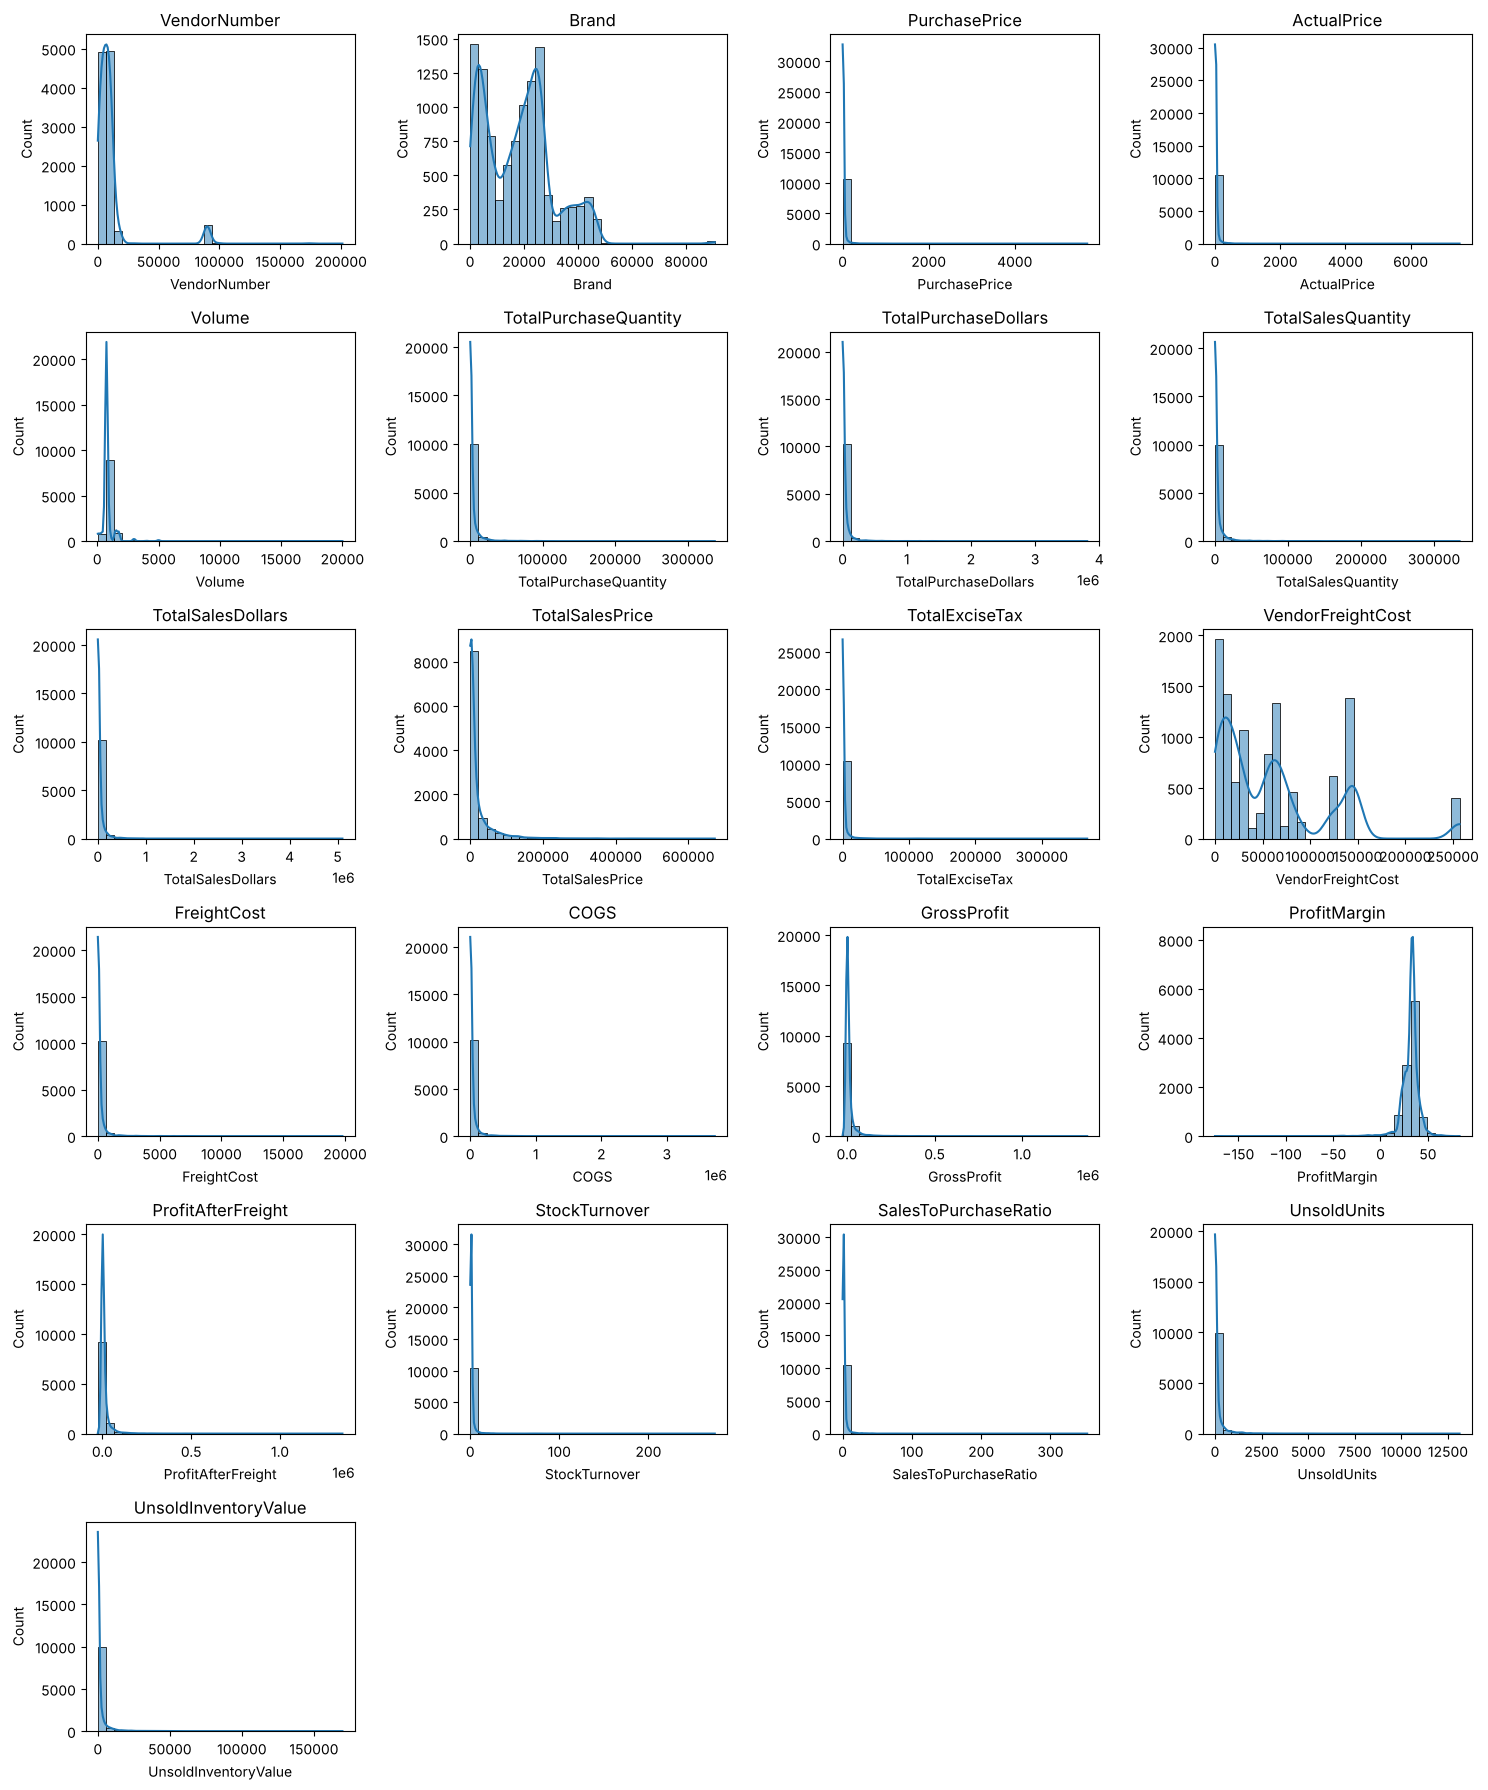

In [4]:
# Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

n_rows = int(np.ceil(len(numerical_cols) / 4))
plt.figure(figsize=(15, 3 * n_rows))
for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, 4, i+1) # Adjust grid layout as needed
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

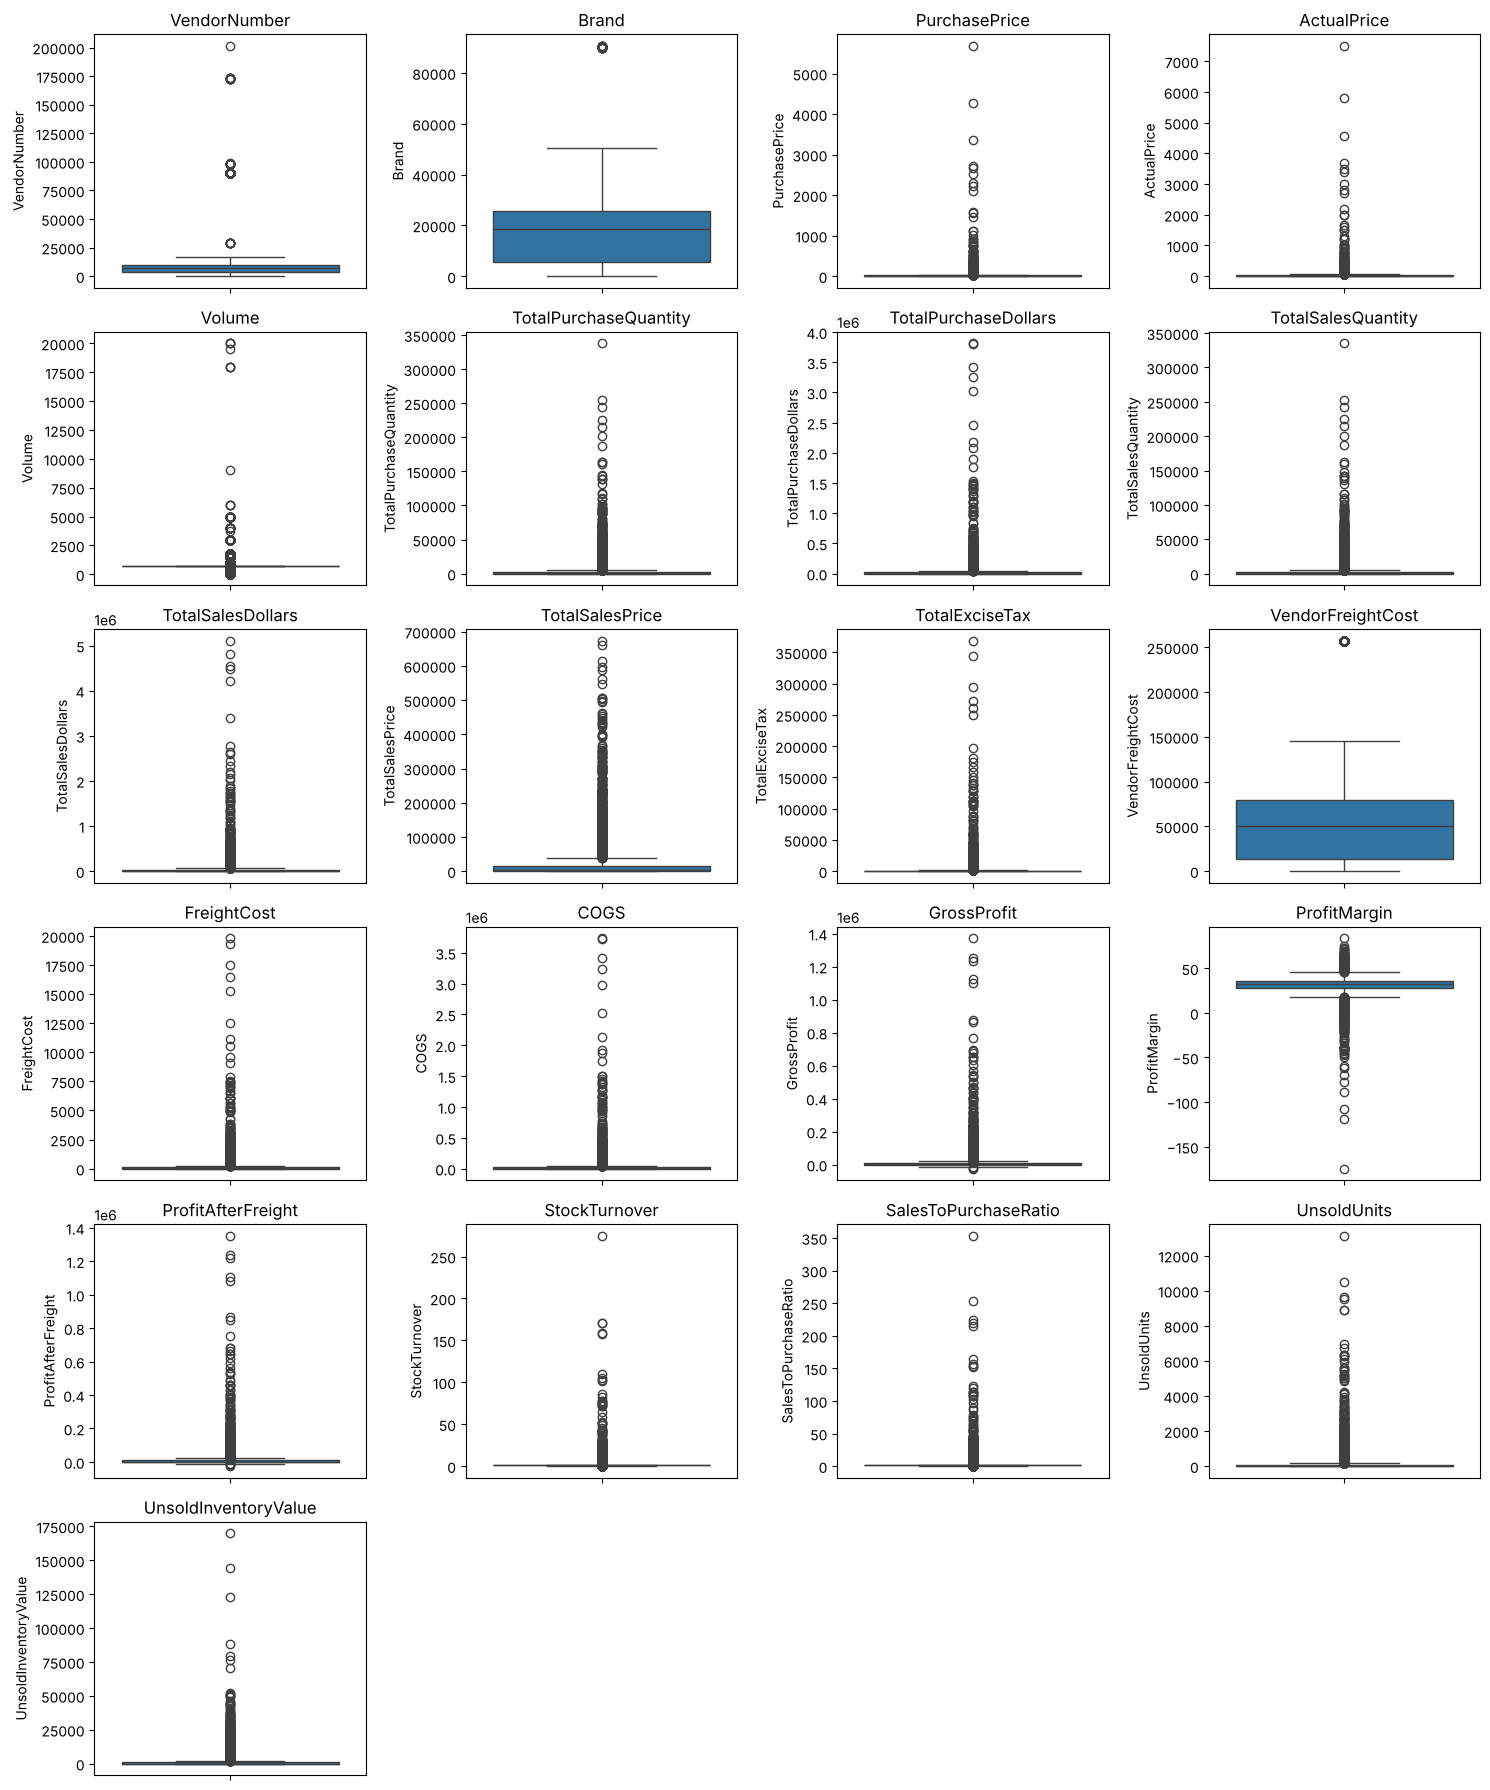

In [5]:
# Outlier Detection with Boxplots
n_rows = int(np.ceil(len(numerical_cols) / 4))
plt.figure(figsize=(15, 3 * n_rows))
for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, 4, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

## Summary Statistics Insights

* **Brands never sold:** 178 of 10,692 brands had purchases but zero sales in the period ($0.28M at cost).
* **Brands sold below cost:** 104 brands have negative gross profit (−$0.27M in total). Under the old definition 1,949 brands looked unprofitable, but most of them had simply bought more units than they sold.
* **Prices:** purchase and retail prices are heavily right-skewed (max $5,681.81 and $7,499.99 against means of $24.39 and $35.64), so medians describe a typical brand better than means.
* **Freight:** after allocation, freight is about 0.5% of purchase cost for almost every vendor; the few exceptions are covered in the freight section below.
* **Stock turnover:** a value above 1 means the brand sold more units than it bought in the period, with the difference coming from opening inventory.

In [6]:
# Keep brands that sold something; margin and turnover are undefined otherwise.
# Brands sold below cost stay in: dropping them would bias every margin figure upward.
print(f"Dropping {(df['TotalSalesQuantity'] == 0).sum()} brands with no sales")
df = df[df['TotalSalesQuantity'] > 0].copy()
df.shape

Dropping 178 brands with no sales


(10514, 23)

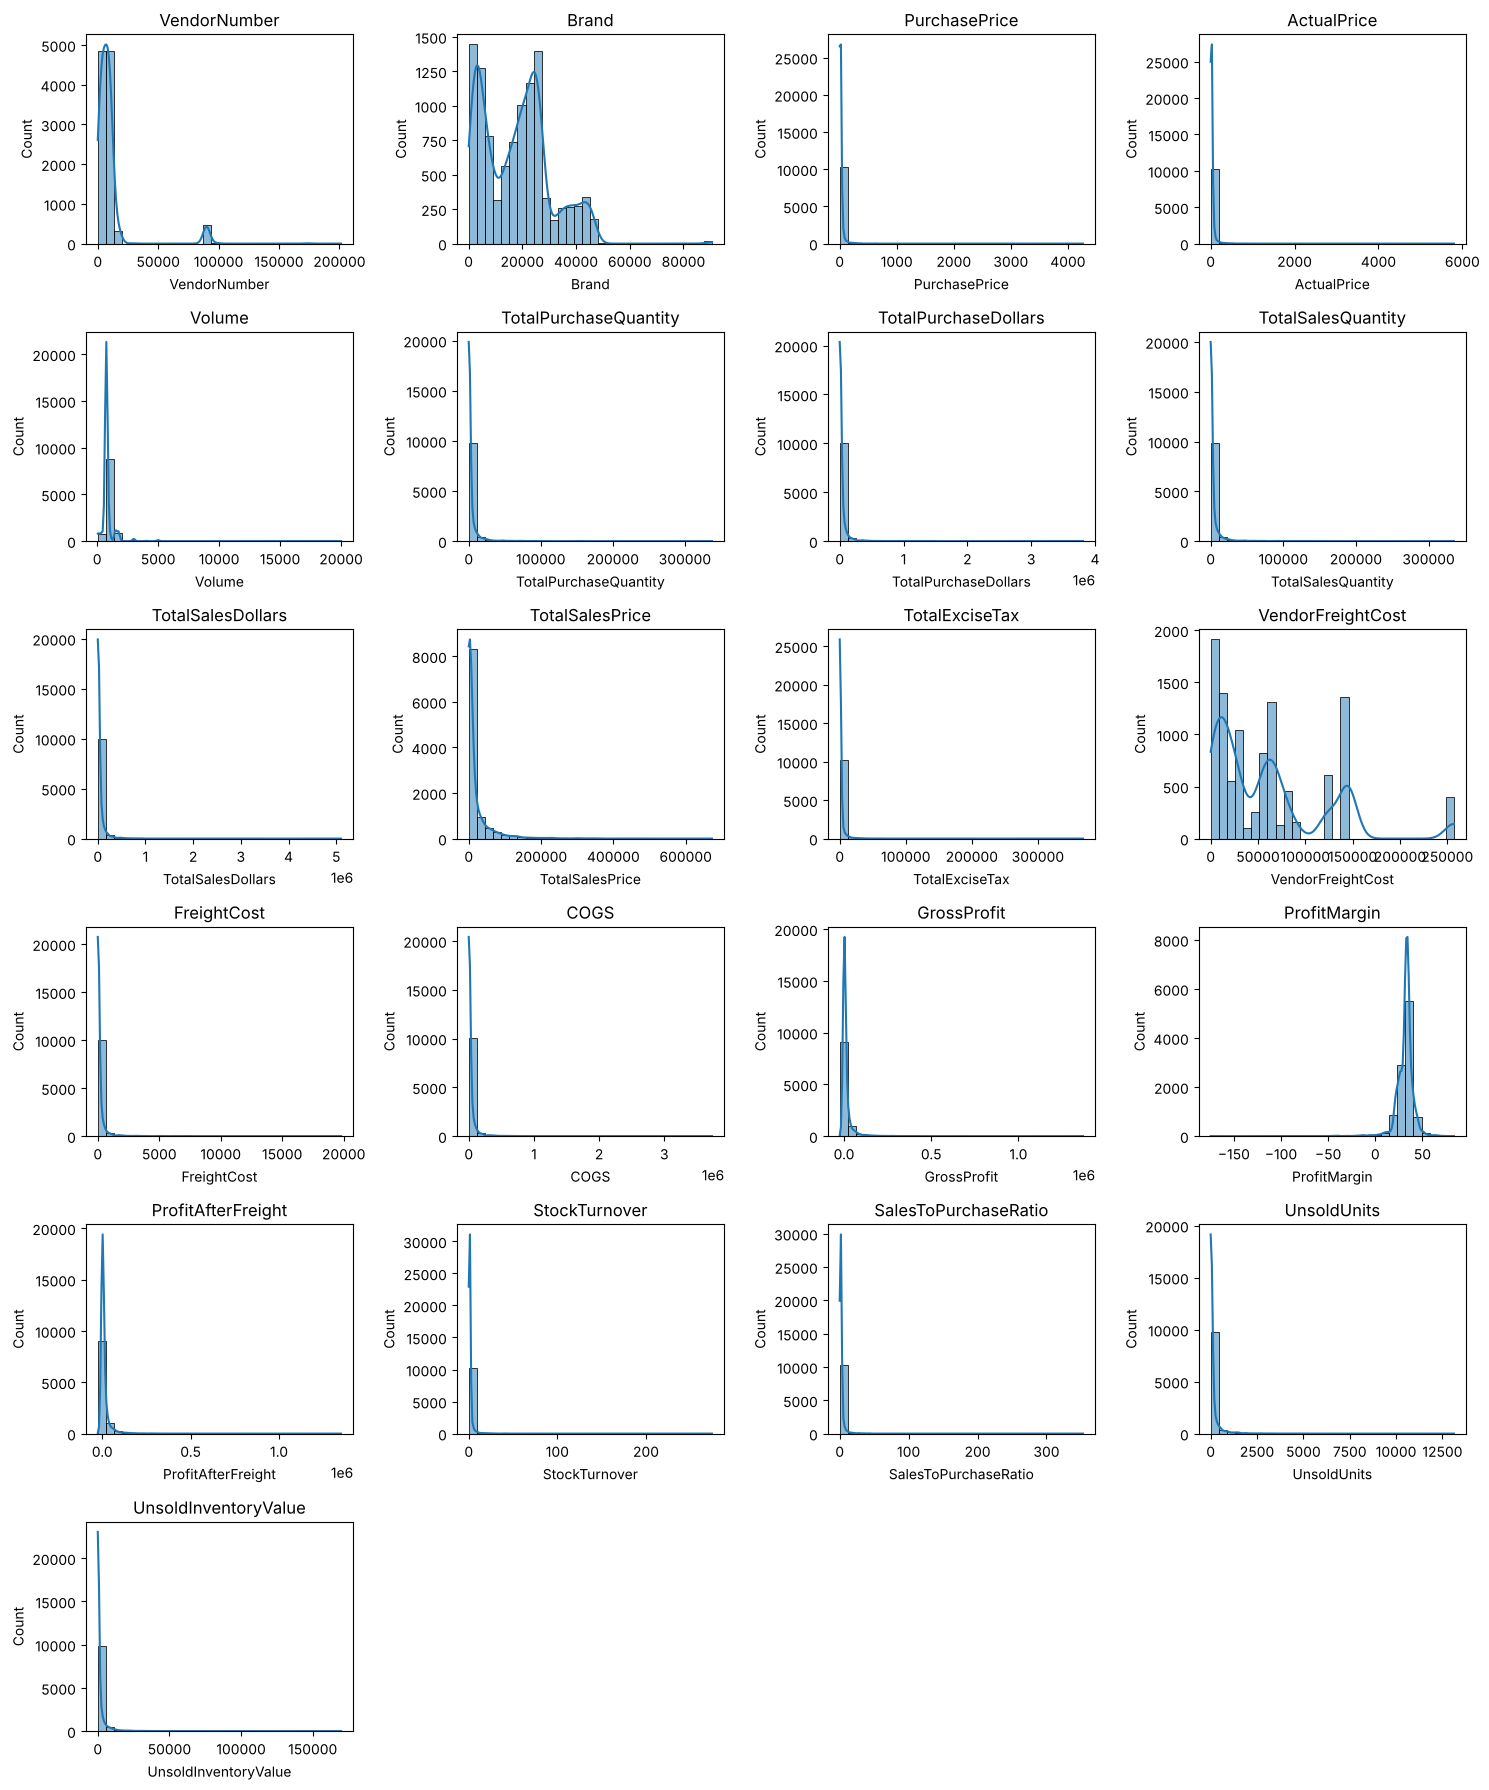

In [7]:
# Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

n_rows = int(np.ceil(len(numerical_cols) / 4))
plt.figure(figsize=(15, 3 * n_rows))
for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, 4, i+1) # Adjust grid layout as needed
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

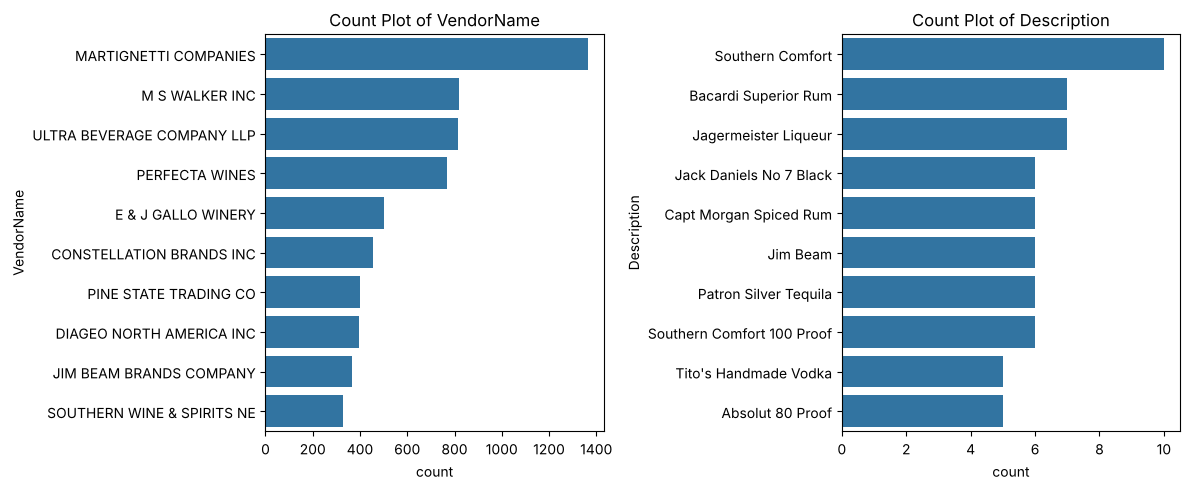

In [8]:
# Count Plots for Categorical Columns
categorical_cols = ["VendorName", "Description"]

plt.figure(figsize=(12, 5))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i+1)
    sns.countplot(y=df[col], order=df[col].value_counts().index[:10]) # Top 10 categories
    plt.title(f"Count Plot of {col}")
plt.tight_layout()
plt.show()

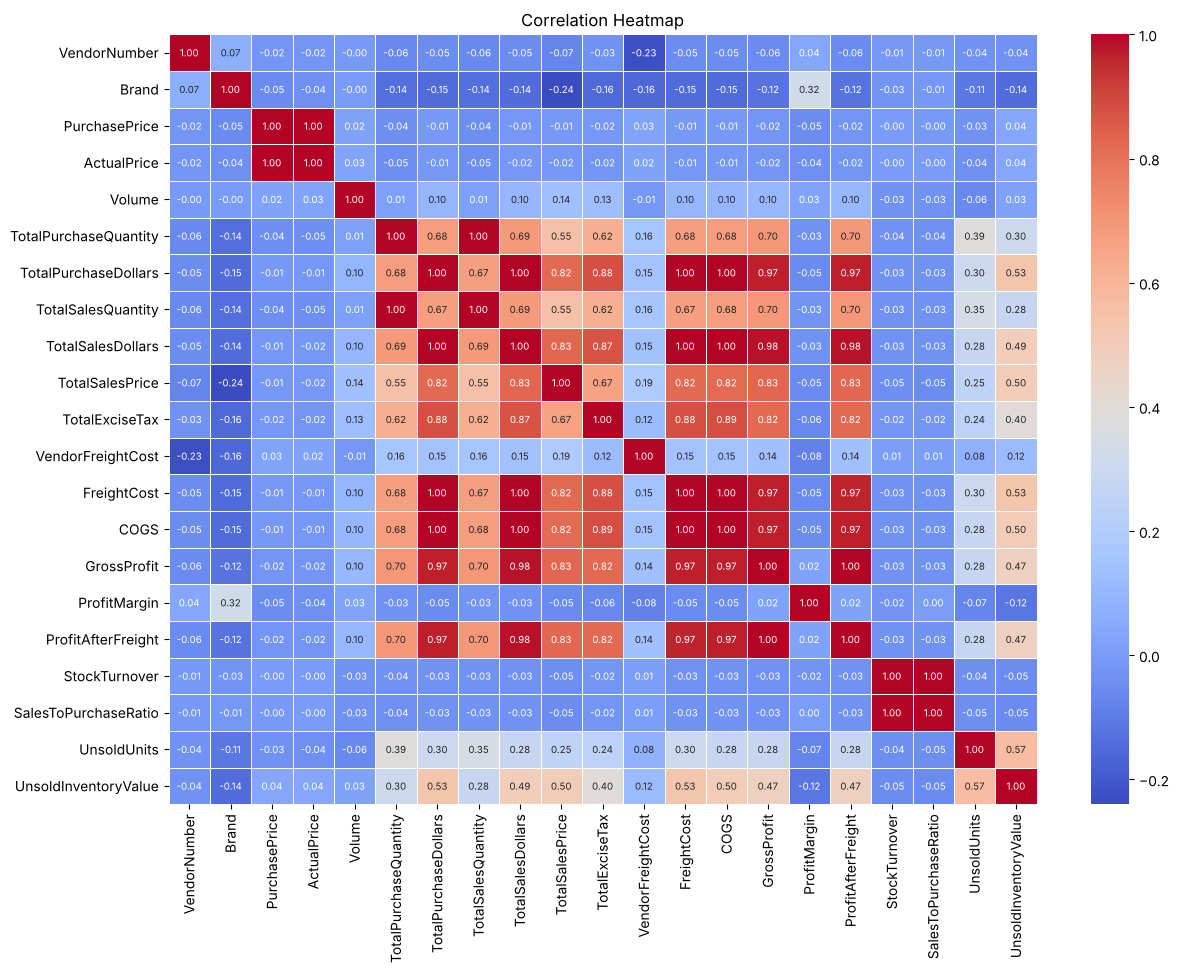

In [9]:
# Correlation Heatmap
numerical_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(14, 10))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, annot_kws={"size": 7})
plt.title("Correlation Heatmap")
plt.show()

### Correlation Insights

* **Price does not predict sales or profit.** PurchasePrice correlates −0.013 with TotalSalesDollars and −0.018 with GrossProfit.
* **Purchases track sales closely** (0.999 between purchase and sales quantity): stores largely restock what they sell.
* **Margin is unrelated to volume.** ProfitMargin correlates −0.029 with TotalSalesDollars, so big and small sellers earn similar margins.
* **FreightCost mirrors sales (0.996)** because freight is a near-flat share of purchase cost (see the freight section), so it adds no separate signal at brand level.
* **StockTurnover** is barely correlated with anything (all |r| < 0.05).

In [10]:
print(f"Revenue:       ${df['TotalSalesDollars'].sum()/1e6:,.2f}M")
print(f"COGS:          ${df['COGS'].sum()/1e6:,.2f}M")
print(f"Gross profit:  ${df['GrossProfit'].sum()/1e6:,.2f}M")
print(f"Gross margin:  {df['GrossProfit'].sum()/df['TotalSalesDollars'].sum()*100:.1f}% (revenue-weighted)")
print(f"Freight:       ${df['FreightCost'].sum()/1e6:,.2f}M ({df['FreightCost'].sum()/df['TotalPurchaseDollars'].sum()*100:.2f}% of purchases)")

Revenue:       $451.62M
COGS:          $313.15M
Gross profit:  $138.47M
Gross margin:  30.7% (revenue-weighted)
Freight:       $1.64M (0.51% of purchases)


### Data Analysis
##### Identify brands that need Promotional or Pricing Adjustments which exhibit lower sales performance but higher profit margins.

In [11]:
brand_performance = df.groupby('Description').agg({
    'TotalSalesDollars' : 'sum',
    'GrossProfit' : 'sum'}).reset_index()
brand_performance['ProfitMargin'] = brand_performance['GrossProfit'] / brand_performance['TotalSalesDollars'] * 100

In [12]:
low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.15)
high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.85)

In [13]:
low_sales_threshold

np.float64(341.84000000000003)

In [14]:
high_margin_threshold

np.float64(37.99423044289836)

In [15]:
# Filter brands with low sales but high profit margins
target_brands = brand_performance[
    (brand_performance['TotalSalesDollars'] <= low_sales_threshold) & 
    (brand_performance['ProfitMargin'] >= high_margin_threshold)
]

print("Brands with Low Sales but High Profit Margins:")
display(target_brands.sort_values('TotalSalesDollars'))

Brands with Low Sales but High Profit Margins:


,Description,TotalSalesDollars,GrossProfit,ProfitMargin
1424,Camelot Chard,9.99,4.55,45.545546
7642,Santa Rita Organic Svgn Bl,9.99,6.64,66.466466
2384,Clos Amador Brut Cava,13.99,6.25,44.674768
2497,Concannon Glen Ellen Wh Zin,15.95,9.35,58.620690
4172,Hacienda Zargon Merlot,19.98,8.96,44.844845
...,...,...,...,...
5647,Maggio Cab Svgn,333.66,128.64,38.554217
366,Apimed Trnava Mead,335.70,134.70,40.125112
3925,Girasole Chard,335.76,129.36,38.527520
4209,Hardys Whiskers Blake Tawny,335.76,148.80,44.317370


In [16]:
print(f"{len(target_brands)} brands, ${target_brands['TotalSalesDollars'].sum():,.0f} in combined sales, "
      f"${target_brands['GrossProfit'].sum():,.0f} in combined gross profit")

134 brands, $21,206 in combined sales, $9,560 in combined gross profit


In [17]:
brand_performance = brand_performance[brand_performance['TotalSalesDollars']<10000] # for better visualization

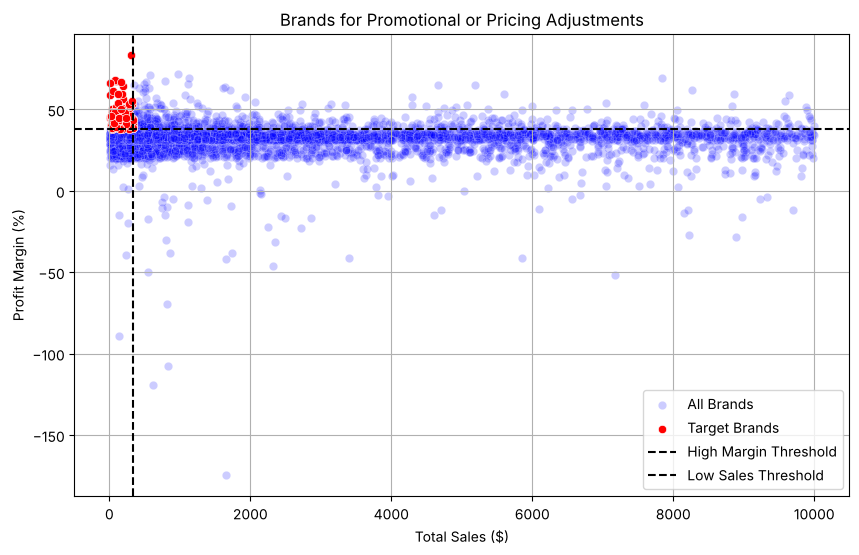

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=brand_performance, x='TotalSalesDollars', y='ProfitMargin', color="blue", label="All Brands", alpha = 0.2)
sns.scatterplot(data=target_brands, x='TotalSalesDollars', y='ProfitMargin', color="red", label="Target Brands")

plt.axhline(high_margin_threshold, linestyle='--', color='black', label="High Margin Threshold")
plt.axvline(low_sales_threshold, linestyle='--', color='black', label="Low Sales Threshold")

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.show()

**Finding:** 134 brands sit in the low-sales, high-margin corner (sales ≤ $342, margin ≥ 38%). Together they sold $21,206 and earned $9,560 in gross profit, under 0.01% of the $138.5M total, so even doubling their sales would add less than $10K.

They are not a meaningful profit lever. For comparison, one percentage point of margin on the top 10 brands (about $57M in sales) is worth roughly $570K. The original "198 hidden gems" result came from margins inflated by the old gross-profit definition.

#### Which vendors and brands demonstrate the highest sales performance?

In [19]:
def format_dollars(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"{value / 1_000:.2f}K"
    else:
        return str(value)

In [20]:
# Top Vendors & Brands by Sales Performance
top_vendors = df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)
top_brands = df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)

top_vendors

VendorName
DIAGEO NORTH AMERICA INC      6.873983e+07
MARTIGNETTI COMPANIES         4.096012e+07
PERNOD RICARD USA             3.227954e+07
JIM BEAM BRANDS COMPANY       3.189862e+07
BACARDI USA INC               2.500537e+07
CONSTELLATION BRANDS INC      2.446713e+07
E & J GALLO WINERY            1.855377e+07
BROWN-FORMAN CORP             1.847661e+07
ULTRA BEVERAGE COMPANY LLP    1.780265e+07
M S WALKER INC                1.543607e+07
Name: TotalSalesDollars, dtype: float64

In [21]:
top_brands

Description
Jack Daniels No 7 Black    7964746.76
Tito's Handmade Vodka      7399657.58
Grey Goose Vodka           7209608.06
Capt Morgan Spiced Rum     6356320.62
Absolut 80 Proof           6244752.03
Jameson Irish Whiskey      5715759.69
Ketel One Vodka            5070083.56
Baileys Irish Cream        4150122.07
Kahlua                     3604858.66
Tanqueray                  3456697.90
Name: TotalSalesDollars, dtype: float64

In [22]:
top_brands.apply(lambda x : format_dollars(x))

Description
Jack Daniels No 7 Black    7.96M
Tito's Handmade Vodka      7.40M
Grey Goose Vodka           7.21M
Capt Morgan Spiced Rum     6.36M
Absolut 80 Proof           6.24M
Jameson Irish Whiskey      5.72M
Ketel One Vodka            5.07M
Baileys Irish Cream        4.15M
Kahlua                     3.60M
Tanqueray                  3.46M
Name: TotalSalesDollars, dtype: str

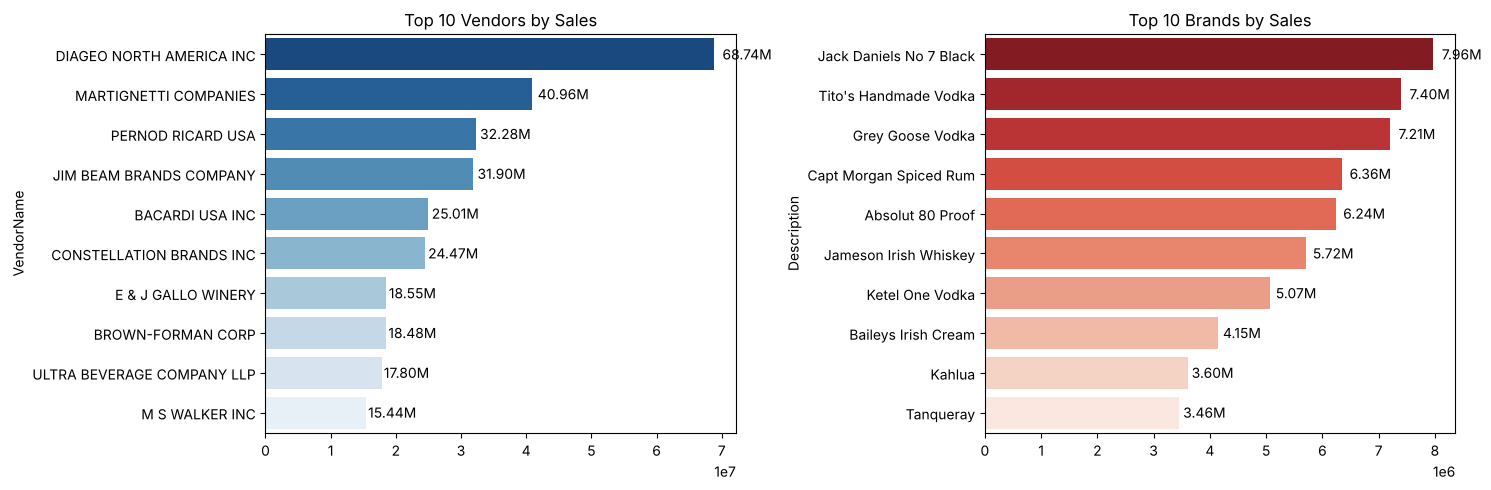

In [23]:
plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)
ax1 = sns.barplot(y=top_vendors.index, x=top_vendors.values, palette="Blues_r")
plt.title("Top 10 Vendors by Sales")

for bar in ax1.patches:
    ax1.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')

# Plot for Top Brands
plt.subplot(1, 2, 2)
ax2 = sns.barplot(y=top_brands.index.astype(str), x=top_brands.values, palette="Reds_r")
plt.title("Top 10 Brands by Sales")

for bar in ax2.patches:
    ax2.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()

#### Which vendors contribute the most to total purchase dollars?

In [24]:
vendor_performance = df.groupby('VendorName').agg({
    'TotalPurchaseDollars':'sum',
    'GrossProfit':'sum',
    'TotalSalesDollars':'sum'
}).reset_index()
vendor_performance.shape

(124, 4)

In [25]:
vendor_performance['PurchaseContribution%'] = vendor_performance['TotalPurchaseDollars'] / vendor_performance['TotalPurchaseDollars'].sum()*100  

In [26]:
vendor_performance = round(vendor_performance.sort_values('PurchaseContribution%', ascending = False),2)

In [27]:
# Display Top 10 Vendors
top_vendors = vendor_performance.head(10)
top_vendors['TotalSalesDollars'] = top_vendors['TotalSalesDollars'].apply(format_dollars)
top_vendors['TotalPurchaseDollars'] = top_vendors['TotalPurchaseDollars'].apply(format_dollars)
top_vendors['GrossProfit'] = top_vendors['GrossProfit'].apply(format_dollars)

top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
27,DIAGEO NORTH AMERICA INC,50.96M,18.76M,68.74M,15.84
61,MARTIGNETTI COMPANIES,27.82M,14.03M,40.96M,8.65
49,JIM BEAM BRANDS COMPANY,24.20M,8.55M,31.90M,7.53
72,PERNOD RICARD USA,24.12M,8.71M,32.28M,7.50
7,BACARDI USA INC,17.62M,7.13M,25.01M,5.48
22,CONSTELLATION BRANDS INC,15.57M,9.13M,24.47M,4.84
13,BROWN-FORMAN CORP,13.53M,5.23M,18.48M,4.21
111,ULTRA BEVERAGE COMPANY LLP,13.10M,5.37M,17.80M,4.07
32,E & J GALLO WINERY,12.29M,6.58M,18.55M,3.82
57,M S WALKER INC,10.88M,4.97M,15.44M,3.38


In [28]:
top_vendors['Cumulative_Contribution%'] = top_vendors['PurchaseContribution%'].cumsum()
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%,Cumulative_Contribution%
27,DIAGEO NORTH AMERICA INC,50.96M,18.76M,68.74M,15.84,15.84
61,MARTIGNETTI COMPANIES,27.82M,14.03M,40.96M,8.65,24.49
49,JIM BEAM BRANDS COMPANY,24.20M,8.55M,31.90M,7.53,32.02
72,PERNOD RICARD USA,24.12M,8.71M,32.28M,7.50,39.52
7,BACARDI USA INC,17.62M,7.13M,25.01M,5.48,45.00
22,CONSTELLATION BRANDS INC,15.57M,9.13M,24.47M,4.84,49.84
13,BROWN-FORMAN CORP,13.53M,5.23M,18.48M,4.21,54.05
111,ULTRA BEVERAGE COMPANY LLP,13.10M,5.37M,17.80M,4.07,58.12
32,E & J GALLO WINERY,12.29M,6.58M,18.55M,3.82,61.94
57,M S WALKER INC,10.88M,4.97M,15.44M,3.38,65.32


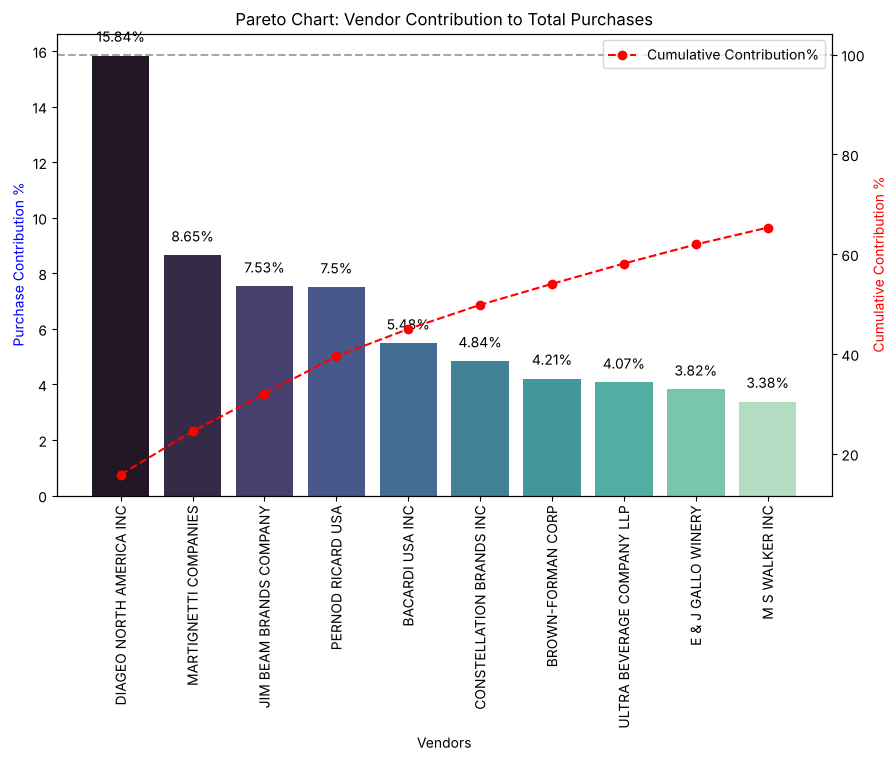

In [29]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for Purchase Contribution%
sns.barplot(x=top_vendors['VendorName'], y=top_vendors['PurchaseContribution%'], palette="mako", ax=ax1)

for i, value in enumerate(top_vendors['PurchaseContribution%']):
    ax1.text(i, value + 0.5, str(value)+'%', ha='center', fontsize=10, color='black')

# Line Plot for Cumulative Contribution%
ax2 = ax1.twinx()
ax2.plot(top_vendors['VendorName'], top_vendors['Cumulative_Contribution%'], color='red', marker='o', linestyle='dashed', label='Cumulative Contribution%')

ax1.set_xticklabels(top_vendors['VendorName'], rotation=90)
ax1.set_ylabel('Purchase Contribution %', color='blue')
ax2.set_ylabel('Cumulative Contribution %', color='red')
ax1.set_xlabel('Vendors')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchases')

ax2.axhline(y=100, color='gray', linestyle='dashed', alpha=0.7)
ax2.legend(loc='upper right')

plt.show()

#### How much of total procurement is dependent on the top vendors?

In [30]:
print(f"Total Purchase Contribution of top 10 vendors is {round(top_vendors['PurchaseContribution%'].sum(),2)} %")

Total Purchase Contribution of top 10 vendors is 65.32 %


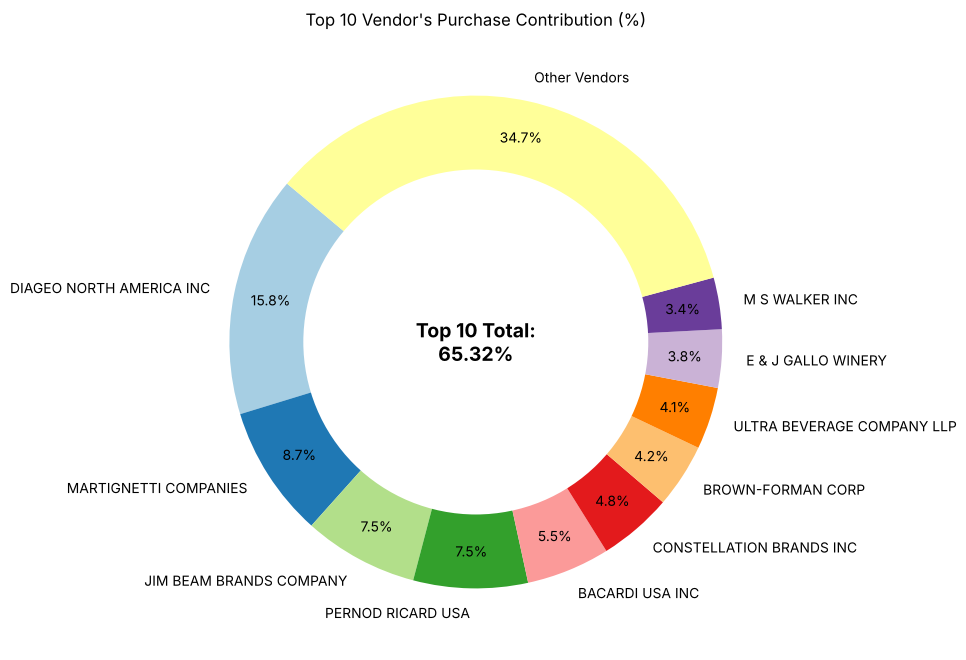

In [31]:
# Extract vendors and their purchase contributions
vendors = list(top_vendors['VendorName'].values)
purchase_contributions = list(top_vendors['PurchaseContribution%'].values)
total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution

# Append "Other Vendors" category to account for the rest of the market
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Donut Chart Initialization
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(purchase_contributions, labels=vendors, autopct='%1.1f%%',
                                  startangle=140, pctdistance=0.85, colors=plt.cm.Paired.colors)

# Draw a white circle in the center to create the "donut" effect
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Add Total Contribution annotation in the center of the donut
plt.text(0, 0, f"Top 10 Total:\n{total_contribution:.2f}%", fontsize=14, fontweight='bold', ha='center', va='center')

plt.title("Top 10 Vendor's Purchase Contribution (%)")
plt.show()

#### Does freight cost vary across vendors?

Freight is recorded on vendor invoices. Freight as a share of purchase cost shows which vendors are expensive to ship from.

In [32]:
freight_by_vendor = df.groupby('VendorName').agg(
    FreightCost=('FreightCost', 'sum'),
    TotalPurchaseDollars=('TotalPurchaseDollars', 'sum')
).reset_index()
freight_by_vendor['FreightPct'] = freight_by_vendor['FreightCost'] / freight_by_vendor['TotalPurchaseDollars'] * 100
print(f"Median vendor freight: {freight_by_vendor['FreightPct'].median():.2f}% of purchases")
freight_by_vendor.sort_values('FreightPct', ascending=False).head(10)

Median vendor freight: 0.51% of purchases


,VendorName,FreightCost,TotalPurchaseDollars,FreightPct
103,TALL SHIP DISTILLERY LLC,259.900000,48445.58,0.536478
120,WESTERN SPIRITS BEVERAGE CO,1933.190000,361249.21,0.535140
44,HIGHLAND WINE MERCHANTS LLC,13.762808,2572.20,0.535060
2,ALTAMAR BRANDS LLC,62.390000,11706.20,0.532965
26,DIAGEO CHATEAU ESTATE WINES,7259.215357,1365372.27,0.531666
17,CANDIA VINEYARDS,194.130000,36588.01,0.530584
52,LABELLE VYDS AND WINERY,778.250000,146839.55,0.530000
37,FLAVOR ESSENCE INC,0.090000,17.00,0.529412
109,TRUETT HURST,1.250000,236.64,0.528229
82,Russian Standard Vodka,732.600000,138907.27,0.527402


**Finding:** every vendor's freight falls between 0.46% and 0.54% of purchase cost (median 0.51%). Freight behaves like a flat charge on purchase value, totalling $1.64M or 0.36% of revenue.

So freight is not a logistics problem and does not separate good vendors from bad ones. The original $543M figure (more than total revenue) was the double-counting bug, not a real cost.

#### Does purchasing in bulk reduce the unit price?

The summary table has a single purchase price per brand, so it cannot show whether buying more of the *same* brand lowers its price. Comparing brands bought in small and large volumes only compares different products.

In [33]:
df["OrderSize"] = pd.qcut(df['TotalPurchaseQuantity'], q=3, labels=["Small", "Medium", "Large"])
print("Purchase prices per brand:", df.groupby('Brand')['PurchasePrice'].nunique().max())
df.groupby('OrderSize', observed=True)['PurchasePrice'].agg(['mean', 'median'])

Purchase prices per brand: 1


,mean,median
OrderSize,,
Small,41.085416,12.71
Medium,17.882941,11.10
Large,11.225070,8.60


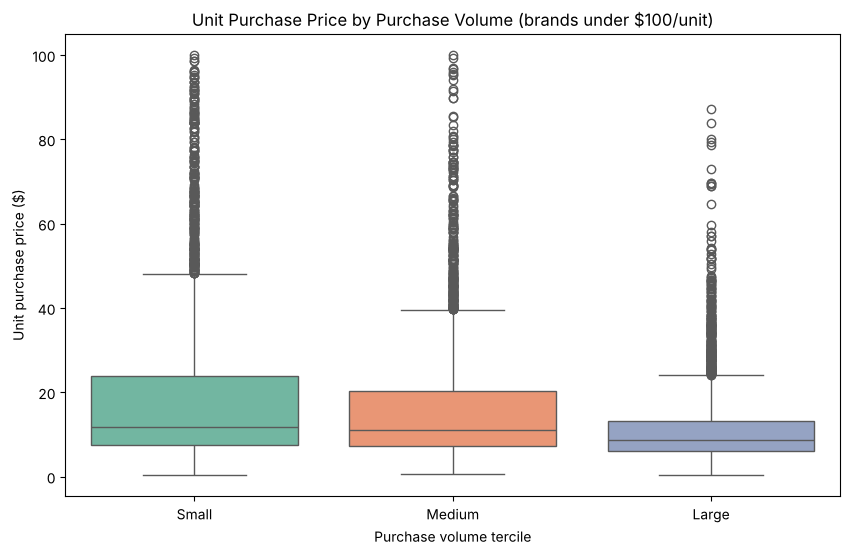

In [34]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[df['PurchasePrice'] < 100], x="OrderSize", y="PurchasePrice", palette="Set2")
plt.title("Unit Purchase Price by Purchase Volume (brands under $100/unit)")
plt.xlabel("Purchase volume tercile")
plt.ylabel("Unit purchase price ($)")
plt.show()

**Finding:** each brand has exactly one purchase price in this data, so there is no evidence of volume discounts. High-volume brands are cheaper (median $8.60 vs $12.71 per unit) because they are different, lower-priced products, such as mass-market spirits against premium wines.

The original "72% lower unit cost from bulk buying" compared different products, not volume tiers of the same product. Testing for bulk discounts would need order-level prices from the raw `purchases` table.

#### Which vendors have low inventory turnover, indicating excess stock and slow moving products?

In [35]:
SLOW_MOVING_TURNOVER = 0.8  # sold less than 80% of the units bought in the period
slow = df[df['StockTurnover'] < SLOW_MOVING_TURNOVER]
print(f"{len(slow)} slow-moving brands")
slow.groupby('VendorName')[['StockTurnover']].mean().sort_values('StockTurnover', ascending=True).head(10)

2435 slow-moving brands


,StockTurnover
VendorName,
TRUETT HURST,0.041667
"IRA GOLDMAN AND WILLIAMS, LLP",0.075000
R.P.IMPORTS INC,0.111111
UNCORKED,0.217238
LABELLE VYDS AND WINERY,0.249383
THE PIERPONT GROUP LLC,0.284722
VINEYARD BRANDS INC,0.290360
LOYAL DOG WINERY,0.308333
HIGHLAND WINE MERCHANTS LLC,0.335069


#### How much capital is locked in unsold inventory per vendor, and which vendors contribute the most to it?

In [36]:
# UnsoldInventoryValue = units bought but not sold in the period, at cost.
# It ignores opening inventory, so it measures inventory build-up, not total stock on hand.
net_change = ((df['TotalPurchaseQuantity'] - df['TotalSalesQuantity']) * df['PurchasePrice']).sum()
print('Inventory build-up (brands where purchases exceeded sales):', format_dollars(df['UnsoldInventoryValue'].sum()))
print('Net change across all brands:', format_dollars(net_change))
print('Tied up in slow-moving brands:', format_dollars(slow['UnsoldInventoryValue'].sum()))

Inventory build-up (brands where purchases exceeded sales): 15.32M
Net change across all brands: 8.47M
Tied up in slow-moving brands: 6.66M


In [37]:
# Capital locked in slow-moving brands, by vendor
inventory_value_per_vendor = slow.groupby("VendorName")["UnsoldInventoryValue"].sum().reset_index()
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(by="UnsoldInventoryValue", ascending=False)
inventory_value_per_vendor['UnsoldInventoryValue'] = inventory_value_per_vendor['UnsoldInventoryValue'].apply(format_dollars)
inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
45,MARTIGNETTI COMPANIES,1.17M
88,ULTRA BEVERAGE COMPANY LLP,892.41K
55,PERFECTA WINES,676.33K
42,M S WALKER INC,558.25K
34,JIM BEAM BRANDS COMPANY,371.88K
20,DIAGEO NORTH AMERICA INC,365.85K
58,PINE STATE TRADING CO,155.28K
8,BROWN-FORMAN CORP,141.95K
15,CONSTELLATION BRANDS INC,141.48K
56,PERNOD RICARD USA,138.03K


**Finding:** brands where purchases outran sales added $15.32M of stock at cost. Netting off brands that drew stock down, inventory grew by $8.47M over the period.

The part worth acting on is the slow-moving group. 2,435 brands sold under 80% of what was bought, tying up $6.66M at cost, plus $0.28M in the 178 brands that never sold (dropped above). Martignetti ($1.17M), Ultra Beverage ($0.89M) and Perfecta Wines ($0.68M) hold the most, so they are the first vendors to review reorder quantities with.

*Caveat:* this ignores opening inventory. The raw `end_inventory` table would give actual stock on hand.

#### What are the 95% confidence intervals for profit margins of top-selling and low-selling brands?

Each row is a brand, so the groups are the top and bottom quartile of brands by sales.

In [38]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)
top_brands_margin = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()
low_brands_margin = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()

In [39]:
def confidence_interval(data, confidence=0.95):
    mean_val = np.mean(data)
    std_err = np.std(data, ddof=1) / np.sqrt(len(data))  # Standard error
    t_critical = stats.t.ppf((1 + confidence) / 2, df=len(data) - 1)
    margin_of_error = t_critical * std_err
    return mean_val, mean_val - margin_of_error, mean_val + margin_of_error

Top-selling brands 95% CI: (31.23, 31.87), Mean: 31.55
Low-selling brands 95% CI: (32.38, 33.00), Mean: 32.69


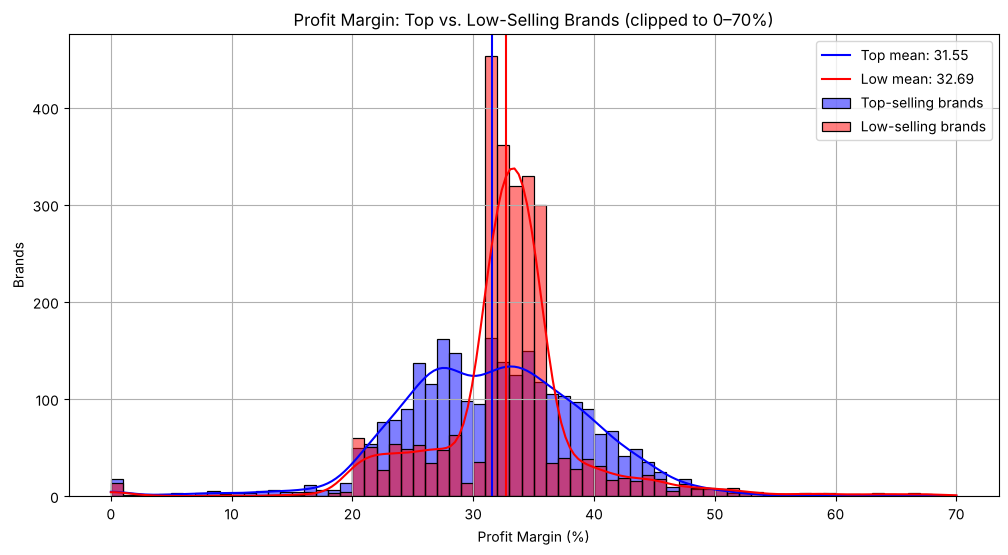

In [40]:
top_mean, top_lower, top_upper = confidence_interval(top_brands_margin)
low_mean, low_lower, low_upper = confidence_interval(low_brands_margin)

print(f"Top-selling brands 95% CI: ({top_lower:.2f}, {top_upper:.2f}), Mean: {top_mean:.2f}")
print(f"Low-selling brands 95% CI: ({low_lower:.2f}, {low_upper:.2f}), Mean: {low_mean:.2f}")

plt.figure(figsize=(12, 6))
bins = np.arange(0, 70, 1)
sns.histplot(top_brands_margin.clip(0, 70), kde=True, color="blue", bins=bins, alpha=0.5, label="Top-selling brands")
plt.axvline(top_mean, color="blue", linestyle="-", label=f"Top mean: {top_mean:.2f}")
sns.histplot(low_brands_margin.clip(0, 70), kde=True, color="red", bins=bins, alpha=0.5, label="Low-selling brands")
plt.axvline(low_mean, color="red", linestyle="-", label=f"Low mean: {low_mean:.2f}")
plt.title("Profit Margin: Top vs. Low-Selling Brands (clipped to 0–70%)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Brands")
plt.legend()
plt.grid(True)
plt.show()

The intervals don't overlap: low-selling brands average a 32.7% margin against 31.6% for top sellers, a gap of about 1 percentage point.

The original analysis reported 41.6% vs 31.2%. That 10-point gap came from the old gross-profit definition and from dropping brands with negative gross profit.

#### Is there a significant difference in profit margins between top-selling and low-selling brands?

**Hypothesis:**

* **$H_0$:** There is no difference in mean profit margin between top-selling and low-selling brands.
* **$H_1$:** The mean profit margins differ.

In [41]:
t_stat, p_value = ttest_ind(top_brands_margin, low_brands_margin, equal_var=False)
diff = low_brands_margin.mean() - top_brands_margin.mean()
pooled_sd = np.sqrt((top_brands_margin.var() + low_brands_margin.var()) / 2)

print(f"T-Statistic: {t_stat:.4f}, P-Value: {p_value:.2e}")
print(f"Difference in means: {diff:.2f} percentage points (Cohen's d = {diff/pooled_sd:.2f})")
if p_value < 0.05:
    print("Reject H0: the margins differ, but check the effect size before acting on it.")
else:
    print("Fail to reject H0: no significant difference in profit margins.")

T-Statistic: -4.9726, P-Value: 6.82e-07
Difference in means: 1.14 percentage points (Cohen's d = 0.14)
Reject H0: the margins differ, but check the effect size before acting on it.


**Result:** the difference is statistically significant (p < 0.001) with about 2,600 brands per group, but the effect is small (1.1 points, Cohen's d ≈ 0.14).

**Implication:** top-selling and low-selling brands run on similar margins. With samples this large a t-test flags differences too small to justify different pricing strategies, so the effect size matters more than the p-value here.